# Minh họa vai trò của hệ số chệch w0 trong hồi quy tuyến tính

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

rng = np.random.default_rng(0)
x = rng.uniform(30, 120, 40)                   # diện tích (m²) của 40 căn nhà
y = 800 + 15 * x + rng.normal(0, 120, x.size)  # giá nhà (triệu đồng)

Có w0: nghiệm bình phương tối thiểu với Xbar = [1, x]

787.4212451528626 15.622136864468935 24.604457940267466


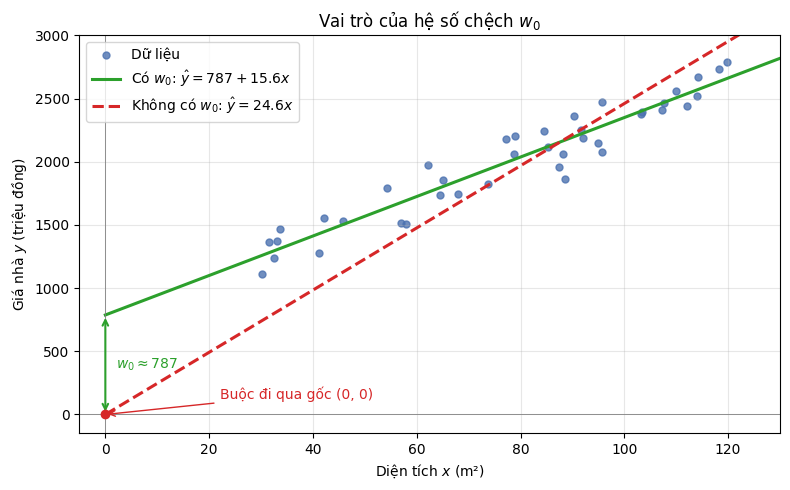

In [2]:
X_bar = np.column_stack([np.ones_like(x), x])
w0, w1 = np.linalg.lstsq(X_bar, y, rcond=None)[0]
# Không có w0: đường thẳng bắt buộc đi qua gốc tọa độ, y = w * x
w_no_bias = (x @ y) / (x @ x)

x_line = np.linspace(0, 130, 200)              # các điểm để vẽ đường thẳng
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=25, color="#4C72B0", alpha=0.8, label="Dữ liệu")
ax.plot(x_line, w0 + w1 * x_line, color="#2CA02C", lw=2.2,
        label=rf"Có $w_0$: $\hat{{y}} = {w0:.0f} + {w1:.1f}x$")
ax.plot(x_line, w_no_bias * x_line, color="#D62728", lw=2.2, ls="--",
        label=rf"Không có $w_0$: $\hat{{y}} = {w_no_bias:.1f}x$")
ax.scatter([0], [0], color="#D62728", zorder=5)
ax.annotate("Buộc đi qua gốc (0, 0)", xy=(0, 0), xytext=(22, 120),
            arrowprops=dict(arrowstyle="->", color="#D62728"), color="#D62728")
ax.annotate("", xy=(0, w0), xytext=(0, 0),
            arrowprops=dict(arrowstyle="<->", color="#2CA02C", lw=1.5))
ax.text(2, w0 / 2, rf"$w_0 \approx {w0:.0f}$", color="#2CA02C", va="center")

ax.set_xlim(-5, 130); ax.set_ylim(-150, 3000)
ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
ax.set_xlabel("Diện tích $x$ (m²)"); ax.set_ylabel("Giá nhà $y$ (triệu đồng)")
ax.set_title("Vai trò của hệ số chệch $w_0$")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "bias_term.png", dpi=150)
print(w0, w1, w_no_bias)